# EDA sản phẩm và quốc gia — Đinh Công Thành

Đồ án đề tài 15, nhóm 4 người — Trường Đại học Sài Gòn, GV Đỗ Như Tài.

**Mục tiêu:** kiểm tra chất lượng giao dịch, sản phẩm nổi bật và mức tập trung theo quốc gia để hỗ trợ diễn giải RFM. Đây là EDA, chưa huấn luyện hay lựa chọn mô hình.

**Ranh giới thời gian:** chỉ kiểm kê kích thước, khoảng ngày và thiếu dữ liệu của toàn file để mô tả nguồn. Toàn bộ phân phối, danh sách mã cần rà soát, bộ lọc và xếp hạng dưới đây dùng `InvoiceDate < CUTOFF`, không khai thác hành vi tương lai. Giai đoạn từ cutoff chỉ dành cho đánh giá ngoài RQ3; không dùng chọn đặc trưng, scaler, ngưỡng hay mô hình.

Nguồn: [UCI Online Retail — Chen (2015)](https://archive.ics.uci.edu/dataset/352/online+retail), [DOI](https://doi.org/10.24432/C5BW33). UCI mô tả đơn giá bằng GBP, hóa đơn bắt đầu C biểu thị hủy. Các số liệu trong notebook được tính từ file, không lấy từ trí nhớ.

In [1]:
from pathlib import Path
import sys

# Hỗ trợ chạy từ thư mục gốc hoặc notebooks/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.config import SEED, CUTOFF, TABLES_DIR, FIGURES_DIR
from src.data_loader import load_raw
from src.eda_product import (
    observation_data, quality_summary, stockcode_audit, positive_product_sales,
    product_ranking, country_profile, plot_product_ranking, plot_distributions,
    plot_special_codes, description_profile, plot_description, plot_countries,
)

np.random.seed(SEED)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 110)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
versions = {p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'matplotlib', 'openpyxl', 'nbclient']}
display({'SEED': SEED, 'CUTOFF': CUTOFF, 'Python': platform.python_version(), 'versions': versions})

{'SEED': 42,
 'CUTOFF': '2011-09-09',
 'Python': '3.13.15',
 'versions': {'pandas': '3.0.6',
  'numpy': '2.5.4',
  'matplotlib': '3.11.2',
  'openpyxl': '3.1.5',
  'nbclient': '0.11.0'}}

## 1. Kiểm kê nguồn và phạm vi quan sát

Đơn vị mỗi dòng là một mặt hàng trong hóa đơn, không phải một khách hàng hay một đơn hàng độc lập. `InvoiceNo`, `StockCode`, `CustomerID` là định danh, không phải biến số liên tục. Dùng `load_raw(use_cache=False)` để lần Restart & Run All đọc lại Excel và không vô tình dùng cache cũ. File gốc phải có tên `data/raw/Online_Retail.xlsx`.

Không điền mô tả hay CustomerID và không xóa trùng ở EDA: thiếu định danh không cản việc cộng hàng hóa/quốc gia, còn dòng trùng có thể là lặp ghi nhận hoặc bán lặp thật. Quyết định làm sạch cho RFM thuộc bước riêng; không suy đoán danh tính khách hàng.

In [2]:
raw = load_raw(use_cache=False)
expected = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
assert raw.columns.tolist() == expected
assert raw.InvoiceDate.notna().all()
obs = observation_data(raw)
assert obs.InvoiceDate.max() < pd.Timestamp(CUTOFF)
assert len(obs) + raw.InvoiceDate.ge(pd.Timestamp(CUTOFF)).sum() == len(raw)

inventory = pd.DataFrame({
    'dtype': raw.dtypes.astype(str), 'missing_full': raw.isna().sum(),
    'missing_observation': obs.isna().sum(),
})
display(inventory)
summary = {
    'rows': len(raw), 'columns': raw.shape[1],
    'date_min': str(raw.InvoiceDate.min()), 'date_max': str(raw.InvoiceDate.max()),
    'observation_rows': len(obs), 'cutoff': CUTOFF,
    'missing_description': int(raw.Description.isna().sum()),
    'missing_customer_id': int(raw.CustomerID.isna().sum()),
    'duplicate_rows': int(raw.duplicated().sum()),
    'uk_raw_row_pct': 100 * raw.Country.eq('United Kingdom').mean(),
    'uk_observation_row_pct': 100 * obs.Country.eq('United Kingdom').mean(),
    'countries_full': raw.Country.nunique(), 'countries_observation': obs.Country.nunique(),
}
display(summary)
quality = quality_summary(obs)
display(quality)
inventory.to_csv(TABLES_DIR / 'eda_prod_inventory.csv', encoding='utf-8-sig')
quality.to_csv(TABLES_DIR / 'eda_prod_quality_observation.csv', index=False, encoding='utf-8-sig')
display(Markdown(
    f"**Nhận xét:** file có {len(raw):,} dòng × {raw.shape[1]} cột, từ {raw.InvoiceDate.min()} đến {raw.InvoiceDate.max()}. "
    f"Có {summary['missing_description']:,} Description thiếu và {summary['missing_customer_id']:,} CustomerID thiếu trên toàn file. "
    f"Phần phân tích tiếp theo chỉ có {len(obs):,} dòng trước cutoff. Các cờ chất lượng có thể chồng lấp; không cộng chúng để tính số dòng bị loại."
))

,dtype,missing_full,missing_observation
InvoiceNo,str,0,0
StockCode,str,0,0
Description,object,1454,1181
Quantity,int64,0,0
InvoiceDate,datetime64[us],0,0
UnitPrice,float64,0,0
CustomerID,Int64,135080,91641
Country,str,0,0


{'rows': 541909,
 'columns': 8,
 'date_min': '2010-12-01 08:26:00',
 'date_max': '2011-12-09 12:50:00',
 'observation_rows': 332447,
 'cutoff': '2011-09-09',
 'missing_description': 1454,
 'missing_customer_id': 135080,
 'duplicate_rows': 5268,
 'uk_raw_row_pct': np.float64(91.43195628786383),
 'uk_observation_row_pct': np.float64(91.19528827151396),
 'countries_full': 38,
 'countries_observation': 37}

,issue,rows,pct_rows
0,Description thiếu/rỗng,1181,0.355245
1,CustomerID thiếu,91641,27.565597
2,Quantity âm,6928,2.083941
3,Quantity bằng 0,0,0.000000
4,UnitPrice âm,2,0.000602
5,UnitPrice bằng 0,1830,0.550464
6,Hóa đơn bắt đầu C,5984,1.799986
7,Dòng trùng hoàn toàn (sau dòng đầu),2561,0.770348


**Nhận xét:** file có 541,909 dòng × 8 cột, từ 2010-12-01 08:26:00 đến 2011-12-09 12:50:00. Có 1,454 Description thiếu và 135,080 CustomerID thiếu trên toàn file. Phần phân tích tiếp theo chỉ có 332,447 dòng trước cutoff. Các cờ chất lượng có thể chồng lấp; không cộng chúng để tính số dòng bị loại.

## 2. Phân phối Quantity, UnitPrice và các ngoại lệ

Biểu đồ trái dùng `sign(x) × log1p(|x|)` **chỉ để hiển thị**, vì log1p trực tiếp không hợp lệ với nhiều giá trị âm. Biểu đồ phải phóng phần dương đến p99 tính trên quan sát; không winsorize, không xóa đuôi và không dùng p99 làm ngưỡng làm sạch. Đây không phải biến đổi đặc trưng RFM; log1p và StandardScaler của mô hình sẽ fit riêng ở giai đoạn quan sát.

,Quantity,UnitPrice
count,332447.000000,332447.000000
mean,9.657404,4.863279
std,190.997724,111.417665
min,-74215.000000,-11062.060000
1%,-2.000000,0.210000
50%,3.000000,2.100000
95%,30.000000,9.960000
99%,100.000000,19.950000
99.9%,480.000000,213.931600
max,74215.000000,38970.000000


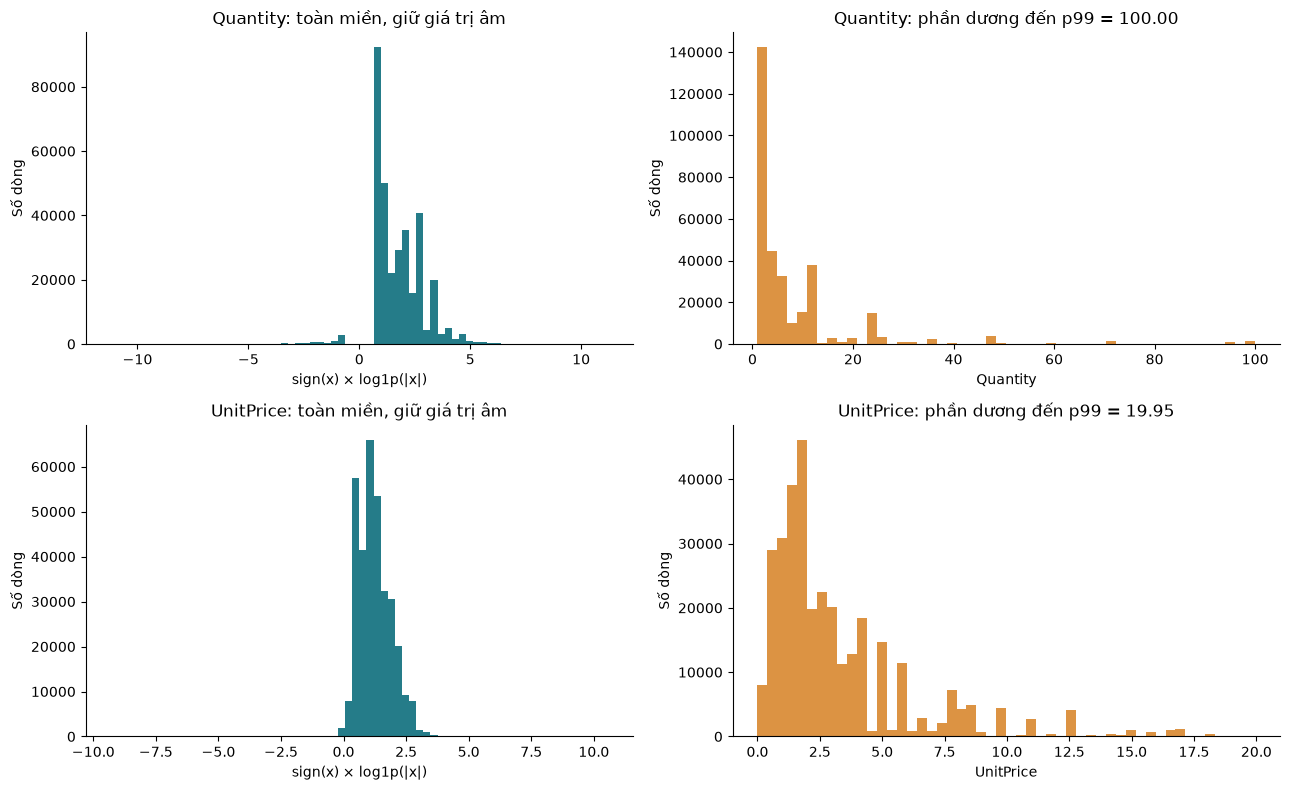

,variable,min,max,positive_p99,positive_rows_above_p99
0,Quantity,-74215.00,74215.0,100.00,3160
1,UnitPrice,-11062.06,38970.0,19.95,3278


**Nhận xét biểu đồ:** Quantity trải từ -74,215 đến 74,215; UnitPrice từ -11,062.06 đến 38,970.00 GBP. Đuôi phải dài và giá trị âm làm trung bình dễ bị chi phối. Phần phóng p99 giúp đọc vùng phổ biến; số dòng ngoài khung được báo trong bảng, không bị loại khỏi các phép tổng hợp.

In [3]:
display(obs[['Quantity', 'UnitPrice']].describe(percentiles=[.01, .5, .95, .99, .999]))
distribution_notes = plot_distributions(obs)
display(distribution_notes)
display(Markdown(
    f"**Nhận xét biểu đồ:** Quantity trải từ {obs.Quantity.min():,} đến {obs.Quantity.max():,}; "
    f"UnitPrice từ {obs.UnitPrice.min():,.2f} đến {obs.UnitPrice.max():,.2f} GBP. "
    "Đuôi phải dài và giá trị âm làm trung bình dễ bị chi phối. Phần phóng p99 giúp đọc vùng phổ biến; "
    "số dòng ngoài khung được báo trong bảng, không bị loại khỏi các phép tổng hợp."
))

In [4]:
extremes = pd.concat([
    obs.nsmallest(5, 'Quantity').assign(case='Quantity thấp nhất'),
    obs.nlargest(5, 'Quantity').assign(case='Quantity cao nhất'),
    obs.nsmallest(5, 'UnitPrice').assign(case='UnitPrice thấp nhất'),
    obs.nlargest(5, 'UnitPrice').assign(case='UnitPrice cao nhất'),
])
display(extremes[['case', *expected]])
display(obs.loc[obs.StockCode.eq('23166') & obs.Quantity.abs().eq(74215)])
extremes.to_csv(TABLES_DIR / 'eda_prod_extremes.csv', index=False, encoding='utf-8-sig')

,case,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61624,Quantity thấp nhất,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom
225529,Quantity thấp nhất,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,<NA>,United Kingdom
225530,Quantity thấp nhất,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.00,<NA>,United Kingdom
4287,Quantity thấp nhất,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838,United Kingdom
225528,Quantity thấp nhất,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.00,<NA>,United Kingdom
61619,Quantity cao nhất,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
74614,Quantity cao nhất,542504,37413,NaN,5568,2011-01-28 12:03:00,0.00,<NA>,United Kingdom
206121,Quantity cao nhất,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72,13135,United Kingdom
220843,Quantity cao nhất,556231,85123A,?,4000,2011-06-09 15:04:00,0.00,<NA>,United Kingdom
97432,Quantity cao nhất,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82,18087,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom


**Nhận xét kiểm tra dòng:** cặp mã 23166, khách 12346, bán 74.215 rồi hủy −74.215 cùng ngày là bằng chứng phải phân biệt bán dương và doanh thu ròng. Các giá lớn như `M`/`AMAZONFEE` phản ánh bút toán/phí; số lượng âm không bắt đầu C và giá 0 còn có thể là điều chỉnh kho. Không kết luận mọi giá trị âm đều sai, cũng không loại đơn hàng sỉ chỉ vì lớn. Các bước tạo Monetary/CancelRate sau này cần quy tắc riêng nhất quán cho mọi mô hình.

## 3. Mã không phải sản phẩm và Description thiếu

Mẫu `5 chữ số + hậu tố chữ tùy chọn` chỉ để tìm **ứng viên rà soát**, không phải quy tắc xóa. Bảng sau lấy mô tả thật, số dòng, số lượng có dấu, giá cao nhất và giá trị có dấu của các mã khác mẫu trong giai đoạn quan sát. Các mã DCGS..., DCGSSGIRL/BOY và PADS có thể là hàng hóa thật nên vẫn giữ.

,rows,descriptions,quantity,signed_value,negative_qty_rows,max_price
StockCode,,,,,,
POST,781,POSTAGE,4467,42232.430,77,8142.750
DOT,570,DOTCOM POSTAGE,1567,120200.100,1,4505.170
M,372,Manual,-1971,-65727.220,166,38970.000
C2,89,CARRIAGE,86,4286.000,2,150.000
D,56,Discount,-1173,-4934.670,56,1867.860
S,55,SAMPLES,-53,-2814.470,54,570.000
AMAZONFEE,25,AMAZON FEE,-21,-150913.850,23,16888.020
BANK CHARGES,24,Bank Charges,-14,-5810.030,19,1050.150
DCGSSGIRL,11,GIRLS PARTY BAG,45,137.850,0,3.290


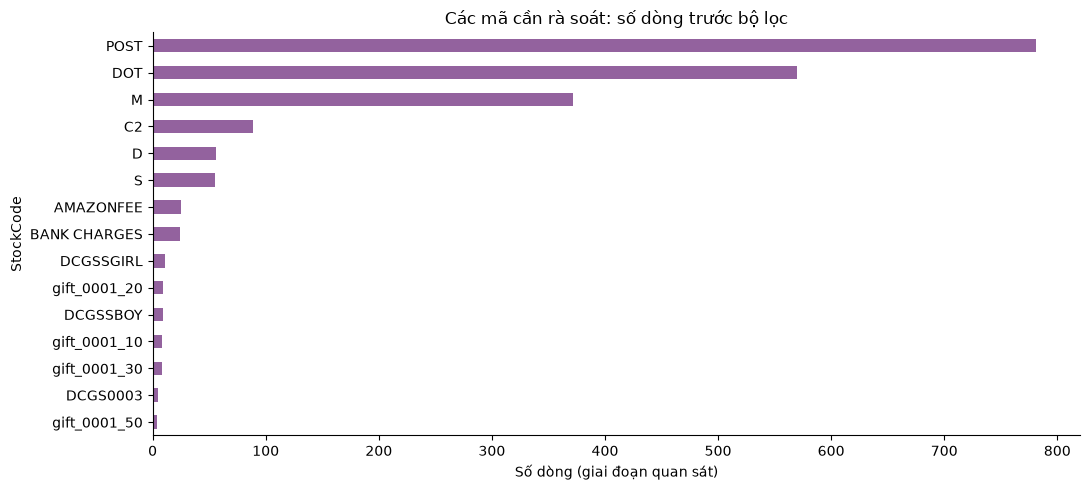

**Nhận xét biểu đồ:** POST có nhiều dòng nhất trong nhóm mã cần rà soát (781 dòng), nhưng độ phổ biến không chứng minh đây là hàng hóa. POST/DOT/C2 là vận chuyển; D là chiết khấu; M/m là bút toán thủ công; cần đối chiếu mô tả trước khi lọc.

In [5]:
audit = stockcode_audit(obs)
display(audit)
audit.to_csv(TABLES_DIR / 'eda_prod_stockcode_audit.csv', encoding='utf-8-sig')
plot_special_codes(audit)
display(Markdown(
    f"**Nhận xét biểu đồ:** {audit.index[0]} có nhiều dòng nhất trong nhóm mã cần rà soát "
    f"({audit.iloc[0]['rows']:,} dòng), nhưng độ phổ biến không chứng minh đây là hàng hóa. "
    "POST/DOT/C2 là vận chuyển; D là chiết khấu; M/m là bút toán thủ công; cần đối chiếu mô tả trước khi lọc."
))

,StockCode,reason,observed_rows,actual_descriptions
0,POST,POSTAGE: cước vận chuyển,781,POSTAGE
1,DOT,DOTCOM POSTAGE: cước vận chuyển,570,DOTCOM POSTAGE
2,C2,CARRIAGE: vận chuyển,89,CARRIAGE
3,D,Discount: chiết khấu,56,Discount
4,M,Manual: bút toán thủ công chưa xác định hàng hóa,372,Manual
5,m,Manual: bút toán thủ công,1,Manual
6,BANK CHARGES,Bank Charges: phí ngân hàng,24,Bank Charges
7,AMAZONFEE,AMAZON FEE: phí nền tảng,25,AMAZON FEE
8,B,Adjust bad debt: điều chỉnh nợ,3,Adjust bad debt
9,CRUK,CRUK Commission: hoa hồng,2,CRUK Commission


,rows,nonpositive_price_pct,negative_quantity_pct,missing_customer_pct
description_status,,,,
Thiếu/rỗng,1181,100.000000,62.489416,100.00000
Có mô tả,331266,0.196519,1.868589,27.30736


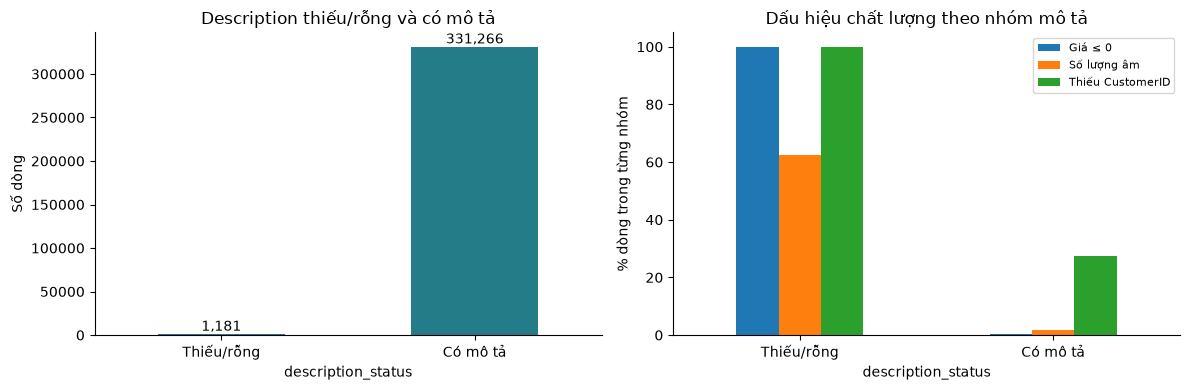

**Nhận xét biểu đồ:** 1,181 dòng quan sát thiếu/rỗng Description. Trong nhóm này, 100.00% có giá ≤ 0 và 100.00% thiếu CustomerID. Thiếu mô tả cần đối chiếu giá/điều chỉnh kho, không tự động điền từ dòng tương lai; gom sản phẩm theo StockCode và chỉ dùng mô tả phổ biến để đặt nhãn.

In [6]:
# Quy tắc EDA cục bộ dựa trên mô tả đã hiển thị, không sửa config/pipeline chung.
excluded_codes = {
    'POST': 'POSTAGE: cước vận chuyển',
    'DOT': 'DOTCOM POSTAGE: cước vận chuyển',
    'C2': 'CARRIAGE: vận chuyển',
    'D': 'Discount: chiết khấu',
    'M': 'Manual: bút toán thủ công chưa xác định hàng hóa',
    'm': 'Manual: bút toán thủ công',
    'BANK CHARGES': 'Bank Charges: phí ngân hàng',
    'AMAZONFEE': 'AMAZON FEE: phí nền tảng',
    'B': 'Adjust bad debt: điều chỉnh nợ',
    'CRUK': 'CRUK Commission: hoa hồng',
    'S': 'SAMPLES: mẫu, tách khỏi hàng bán lẻ',
}
for stockcode in audit.index:
    if stockcode.startswith('gift_'):
        excluded_codes[stockcode] = 'Gift Voucher: phiếu quà tặng, tránh cộng như hàng hóa vật lý'
exclusion_table = pd.DataFrame([
    {'StockCode': key, 'reason': reason, 'observed_rows': int(obs.StockCode.eq(key).sum()),
     'actual_descriptions': audit.loc[key, 'descriptions']}
    for key, reason in excluded_codes.items() if key in audit.index
])
display(exclusion_table)
exclusion_table.to_csv(TABLES_DIR / 'eda_prod_exclusion_reasons.csv', index=False, encoding='utf-8-sig')
description_stats = description_profile(obs)
display(description_stats)
plot_description(description_stats)
display(Markdown(
    f"**Nhận xét biểu đồ:** {description_stats.loc['Thiếu/rỗng', 'rows']:,} dòng quan sát thiếu/rỗng Description. "
    f"Trong nhóm này, {description_stats.loc['Thiếu/rỗng', 'nonpositive_price_pct']:.2f}% có giá ≤ 0 và "
    f"{description_stats.loc['Thiếu/rỗng', 'missing_customer_pct']:.2f}% thiếu CustomerID. "
    "Thiếu mô tả cần đối chiếu giá/điều chỉnh kho, không tự động điền từ dòng tương lai; gom sản phẩm theo StockCode và chỉ dùng mô tả phổ biến để đặt nhãn."
))

## 4. Bộ lọc nhẹ và top sản phẩm

Chỉ ở phần EDA hàng hóa: tách hóa đơn C, Quantity ≤ 0, UnitPrice ≤ 0 và các mã phí/điều chỉnh/phiếu quà tặng đã giải thích ở trên. Các dòng này vẫn tồn tại trong `raw` và `obs` để kiểm tra hoàn/hủy, không bị xóa khỏi nguồn. Giữ CustomerID thiếu, Description thiếu, dòng trùng và ngoại lệ lớn; bảng audit cho thấy tác động từng bước theo thứ tự để tránh đếm trùng số dòng loại.

Doanh thu ở đây là `Quantity × UnitPrice` cộng trên **dòng bán dương hàng hóa**, tính bằng GBP, chưa khấu trừ hoàn/hủy; không gọi đây là doanh thu ròng hay Monetary RFM chính thức. Không lọc UK để tránh làm mất khách ngoài UK trước khi có bằng chứng nghiệp vụ.

,step,remaining_rows,removed_rows
0,Giai đoạn quan sát,332447,0
1,Bỏ hóa đơn C: không phải lượt bán dương,326463,5984
2,Quantity > 0: tách trả hàng/điều chỉnh,325519,944
3,UnitPrice > 0: tách miễn phí/giá lỗi,324631,888
4,Bỏ mã phí/điều chỉnh đã kiểm tra mô tả,323032,1599


,description,quantity,revenue_gbp,rows
StockCode,,,,
23166,MEDIUM CERAMIC TOP STORAGE JAR,76695,80085.65,142
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,37954,9323.90,326
85099B,JUMBO BAG RED RETROSPOT,32609,63121.90,1452
22197,SMALL POPCORN HOLDER,29211,24194.18,864
21212,PACK OF 72 RETROSPOT CAKE CASES,28578,16401.46,976
85123A,WHITE HANGING HEART T-LIGHT HOLDER,28384,78131.48,1641
84879,ASSORTED COLOUR BIRD ORNAMENT,24589,39728.53,970
15036,ASSORTED COLOURS SILK FAN,21663,16742.15,414
22616,PACK OF 12 LONDON TISSUES,19883,5525.51,361


,description,quantity,revenue_gbp,rows
StockCode,,,,
22423,REGENCY CAKESTAND 3 TIER,10710,134162.61,1455
47566,PARTY BUNTING,15854,85811.74,1387
23166,MEDIUM CERAMIC TOP STORAGE JAR,76695,80085.65,142
85123A,WHITE HANGING HEART T-LIGHT HOLDER,28384,78131.48,1641
85099B,JUMBO BAG RED RETROSPOT,32609,63121.90,1452
22502,PICNIC BASKET WICKER SMALL,1937,51412.72,467
84879,ASSORTED COLOUR BIRD ORNAMENT,24589,39728.53,970
79321,CHILLI LIGHTS,6476,32832.46,425
23298,SPOTTY BUNTING,6110,30818.38,795


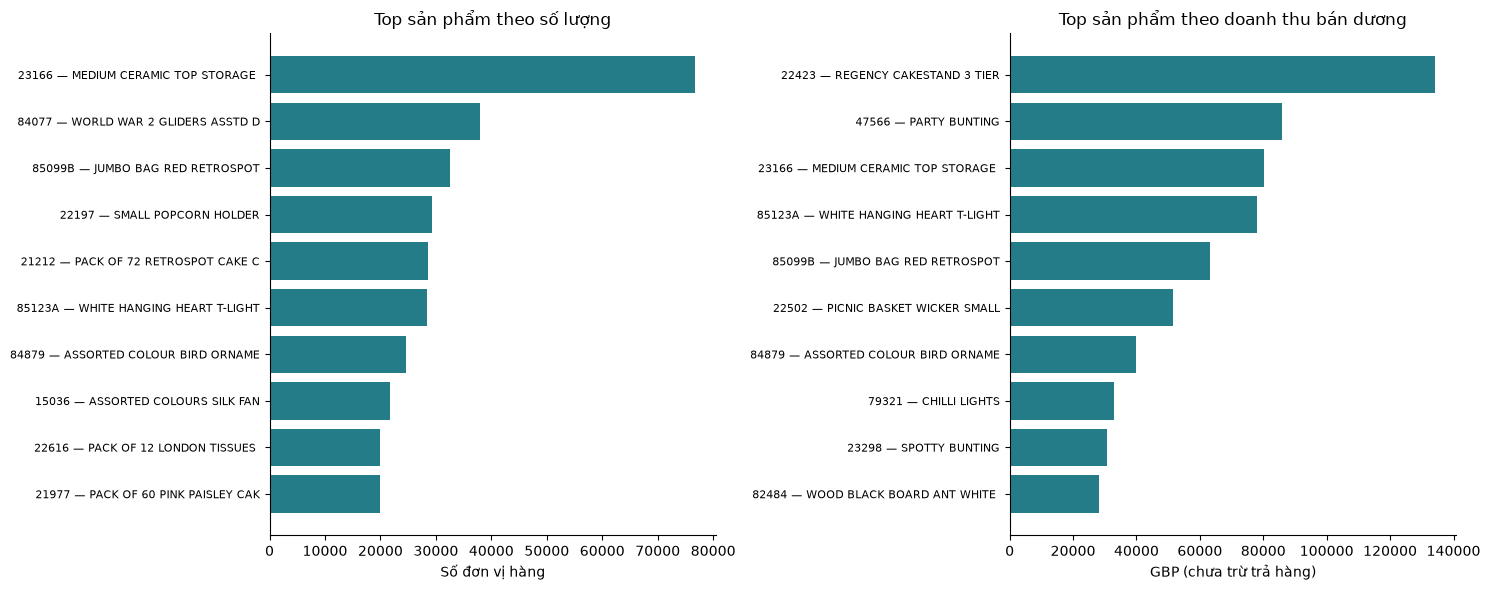

**Nhận xét biểu đồ:** sau lọc còn 323,032 dòng. Mã 23166 dẫn đầu số lượng (76,695 đơn vị), còn 22423 dẫn đầu doanh thu bán dương (134,162.61 GBP). Hai thứ hạng đo hai khía cạnh khác nhau; giá trị đơn vị và đơn sỉ có thể tạo khác biệt. Cặp bán–hủy đã nêu cho thấy thứ hạng bán dương cần được đọc cùng kiểm tra hoàn/hủy.

In [7]:
sales, filter_audit = positive_product_sales(obs, excluded_codes)
display(filter_audit)
assert sales.InvoiceDate.lt(pd.Timestamp(CUTOFF)).all()
assert sales.Quantity.gt(0).all() and sales.UnitPrice.gt(0).all()
assert not sales.StockCode.isin(excluded_codes).any()
assert len(obs) == len(sales) + filter_audit.removed_rows.sum()
filter_audit.to_csv(TABLES_DIR / 'eda_prod_filter_audit.csv', index=False, encoding='utf-8-sig')
ranking = product_ranking(sales)
display(ranking.nlargest(10, 'quantity'))
display(ranking.nlargest(10, 'revenue_gbp'))
ranking.to_csv(TABLES_DIR / 'eda_prod_product_ranking.csv', encoding='utf-8-sig')
plot_product_ranking(ranking)
qty_leader = ranking.quantity.idxmax()
revenue_leader = ranking.revenue_gbp.idxmax()
display(Markdown(
    f"**Nhận xét biểu đồ:** sau lọc còn {len(sales):,} dòng. Mã {qty_leader} dẫn đầu số lượng "
    f"({ranking.loc[qty_leader, 'quantity']:,} đơn vị), còn {revenue_leader} dẫn đầu doanh thu bán dương "
    f"({ranking.loc[revenue_leader, 'revenue_gbp']:,.2f} GBP). "
    "Hai thứ hạng đo hai khía cạnh khác nhau; giá trị đơn vị và đơn sỉ có thể tạo khác biệt. "
    "Cặp bán–hủy đã nêu cho thấy thứ hạng bán dương cần được đọc cùng kiểm tra hoàn/hủy."
))

In [8]:
# Chỉ chẩn đoán độ nhạy, không thay đổi top hay bộ lọc chính.
sales_duplicate = sales.duplicated(subset=expected)
qty_without_duplicates = product_ranking(sales.loc[~sales_duplicate]).quantity.idxmax()
pair_revenue = sales.loc[sales.StockCode.eq('23166') & sales.Quantity.eq(74215), 'line_value'].sum()
display(Markdown(
    f"**Độ nhạy:** có {sales_duplicate.sum():,} dòng bán dương trùng hoàn toàn sau dòng đầu. "
    f"Nếu tạm bỏ chúng, mã dẫn đầu số lượng là {qty_without_duplicates}. "
    f"Riêng lượt bán 74.215 đơn vị mã 23166 đóng góp {pair_revenue:,.2f} GBP vào tổng bán dương, "
    "dù có bút toán hủy tương ứng. Cần xem chính sách hoàn/hủy và dòng trùng ở bước làm sạch, không tự suy ra sai số chỉ từ độ lớn."
))

**Độ nhạy:** có 2,533 dòng bán dương trùng hoàn toàn sau dòng đầu. Nếu tạm bỏ chúng, mã dẫn đầu số lượng là 23166. Riêng lượt bán 74.215 đơn vị mã 23166 đóng góp 77,183.60 GBP vào tổng bán dương, dù có bút toán hủy tương ứng. Cần xem chính sách hoàn/hủy và dòng trùng ở bước làm sạch, không tự suy ra sai số chỉ từ độ lớn.

## 5. Phân bố quốc gia: mẫu số và quyết định phạm vi

So sánh tỷ trọng **dòng** UK trên toàn file (kiểm kê nguồn), giai đoạn quan sát chưa lọc và dòng bán dương quan sát. Phân bố doanh thu dùng cùng tập dòng bán dương ở mục 4. Số khách theo quốc gia chỉ đếm ID có sẵn; một ID có thể xuất hiện ở nhiều quốc gia nên không cộng các số khách để suy ra tổng khách duy nhất.

,rows,invoices,customers,revenue_gbp,row_pct,revenue_pct
Country,,,,,,
United Kingdom,295392,11655,3025,5268475.862,91.443572,83.920598
Germany,5589,278,74,134133.090,1.730169,2.136582
EIRE,4831,176,3,191218.640,1.495517,3.045887
France,4757,234,70,109561.520,1.472610,1.745186
Spain,1589,59,22,36276.100,0.491902,0.577835
Netherlands,1558,56,8,181257.080,0.482305,2.887211
Belgium,1199,66,24,21652.730,0.371171,0.344902
Switzerland,1149,33,17,30380.900,0.355692,0.483932
Australia,941,41,9,111760.750,0.291302,1.780217


,population,uk_row_pct
0,"Toàn file, chưa lọc (chỉ kiểm kê)",91.431956
1,"Quan sát, chưa lọc",91.195288
2,"Quan sát, bán dương hàng hóa",91.443572


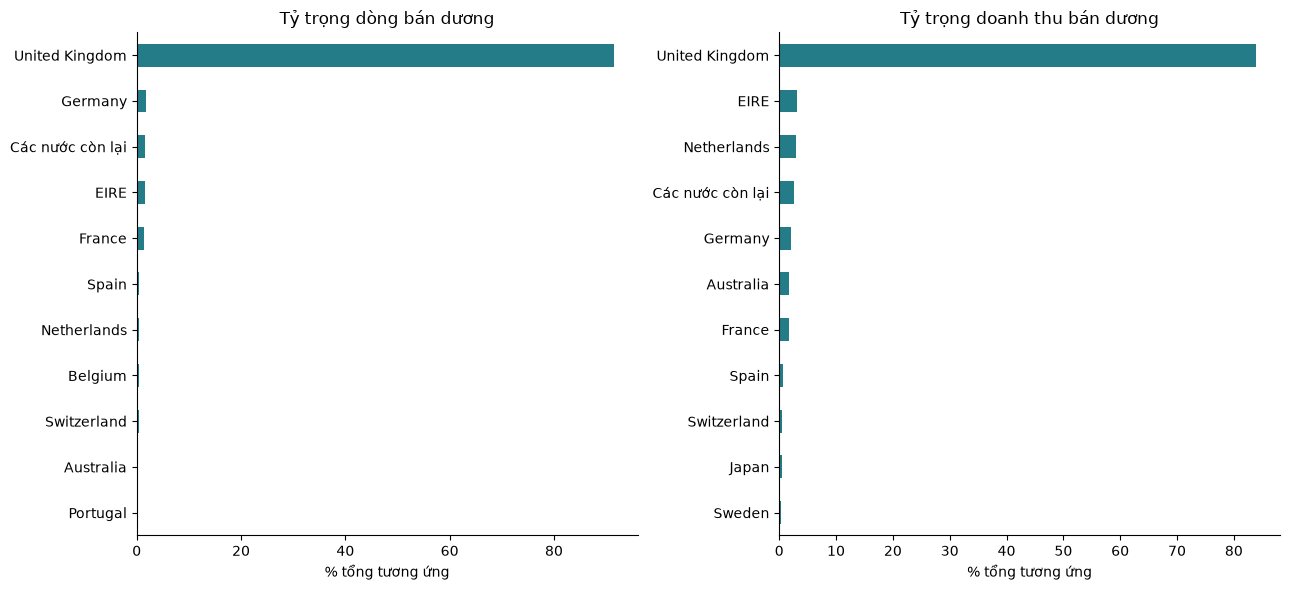

**Nhận xét biểu đồ:** UK chiếm 91.44% dòng và 83.92% doanh thu bán dương hàng hóa trước cutoff; toàn file chưa lọc có 91.43% dòng UK. Tập bán dương quan sát có 37 quốc gia. Tập trung mạnh ở UK khiến hồ sơ cụm tổng thể dễ phản ánh thị trường này; tỷ trọng dòng và doanh thu khác nhau cho thấy chỉ đếm dòng chưa đủ mô tả giá trị khách hàng.

{'non_uk_known_customer_ids': 335, 'known_ids_in_multiple_countries': 6}

In [9]:
countries = country_profile(sales)
display(countries)
countries.to_csv(TABLES_DIR / 'eda_prod_countries.csv', encoding='utf-8-sig')
uk = countries.loc['United Kingdom']
uk_share = pd.DataFrame([
    {'population': 'Toàn file, chưa lọc (chỉ kiểm kê)', 'uk_row_pct': summary['uk_raw_row_pct']},
    {'population': 'Quan sát, chưa lọc', 'uk_row_pct': summary['uk_observation_row_pct']},
    {'population': 'Quan sát, bán dương hàng hóa', 'uk_row_pct': uk.row_pct},
])
display(uk_share)
plot_countries(countries)
display(Markdown(
    f"**Nhận xét biểu đồ:** UK chiếm {uk.row_pct:.2f}% dòng và {uk.revenue_pct:.2f}% doanh thu bán dương hàng hóa "
    f"trước cutoff; toàn file chưa lọc có {summary['uk_raw_row_pct']:.2f}% dòng UK. "
    f"Tập bán dương quan sát có {len(countries)} quốc gia. Tập trung mạnh ở UK khiến hồ sơ cụm tổng thể dễ phản ánh thị trường này; "
    "tỷ trọng dòng và doanh thu khác nhau cho thấy chỉ đếm dòng chưa đủ mô tả giá trị khách hàng."
))
non_uk_ids = sales.loc[sales.is_non_uk, 'CustomerID'].nunique()
multi_country_ids = sales.groupby('CustomerID').Country.nunique().gt(1).sum()
display({'non_uk_known_customer_ids': non_uk_ids, 'known_ids_in_multiple_countries': int(multi_country_ids)})

**Quyết định đề xuất:** giữ khách ở tất cả quốc gia và gắn cờ ngoài UK để **profiling**, chưa tách riêng mô hình UK/ngoài UK. Ngoài UK có ít mẫu hơn và cơ cấu đơn hàng có thể khác; tách ngay làm giảm cỡ mẫu, thay đổi quần thể nghiên cứu và tính so sánh giữa mô hình. Cờ `is_non_uk` hiện chỉ ở bản sao EDA, không tự ý thêm vào RFM/RFM_PLUS đã chốt.

Khi profiling cấp khách hàng, cần quy ước từ giao dịch **trước cutoff** (ví dụ có ít nhất một giao dịch ngoài UK), kiểm tra ID đa quốc gia và thiếu ID. Có thể báo tỷ trọng ngoài UK trong từng cụm để xem cụm đang phân biệt địa lý hay hành vi. Không dùng kết quả chi tiêu/quay lại ở kiểm chứng để quyết định có tách quốc gia hay không.

## 6. Kết luận EDA và liên hệ thực nghiệm

- Phân phối lệch phải và đơn lớn có thể kéo tâm K-Means, làm khoảng cách Ward bị chi phối, hoặc khiến DBSCAN coi khách sỉ là noise. Đây là lý do khảo sát log1p trên đặc trưng khách hàng, không chứng minh mô hình nào tốt nhất và không đủ lý do xóa ngoại lệ.
- Dòng hủy, điều chỉnh, giá 0 và phí cần quy tắc nghiệp vụ riêng. Không bỏ mất lịch sử hủy trước khi tính CancelRate; không đồng nhất doanh thu bán dương EDA với Monetary chính thức.
- Thiếu CustomerID không cản EDA sản phẩm/quốc gia nhưng không thể tạo khách hàng giả để tính RFM. Thiếu Description không nhất thiết thiếu mã sản phẩm.
- UK áp đảo: giữ phạm vi chung và dùng cờ ngoài UK cho diễn giải. Baseline RFM, K-Means, Hierarchical, DBSCAN sau này phải dùng cùng danh sách khách hợp lệ, cùng cửa sổ và cùng đặc trưng/scaler trong từng feature set; báo cả tỷ lệ noise của DBSCAN để tránh lợi thế do bỏ điểm khó.
- Chỉ dùng quan sát để fit log1p/scaler, tuning và đánh giá ổn định theo seed/bootstrap. RQ1/RQ2 cần kết hợp metric nội tại, profiling và ARI; tránh chọn metric cao nhất máy móc. RQ3 dùng dữ liệu từ cutoff để đánh giá chi tiêu/quay lại và Kruskal–Wallis, không quay lại chọn mô hình.

**Giới hạn:** bộ lọc cục bộ là định nghĩa tập hàng hóa phục vụ EDA, không thay thế cleaning pipeline. Các mã lạ chưa xác minh vẫn được giữ; mô tả phổ biến chỉ là nhãn hiển thị, không phải bảng danh mục chuẩn. Không suy ra quan hệ nhân quả hoặc khả năng dự báo từ các biểu đồ này.

In [10]:
summary.update({
    'sales_observation_rows': len(sales),
    'sales_duplicate_rows': int(sales_duplicate.sum()),
    'uk_sales_row_pct': float(uk.row_pct), 'uk_sales_revenue_pct': float(uk.revenue_pct),
    'sales_countries': len(countries),
    'quantity_min_observation': int(obs.Quantity.min()), 'quantity_max_observation': int(obs.Quantity.max()),
    'unit_price_min_observation': float(obs.UnitPrice.min()), 'unit_price_max_observation': float(obs.UnitPrice.max()),
    'top_quantity_code': str(qty_leader), 'top_revenue_code': str(revenue_leader),
    'versions': versions, 'python': platform.python_version(),
})
(TABLES_DIR / 'eda_prod_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(
    '**Tái lập:** dùng kernel có các thư viện trong `requirements.txt`, chọn Kernel → Restart & Run All. '
    'Các kiểm tra ở trên xác nhận cutoff, miền bán dương và đối soát số dòng lọc. '
    'Năm hình được lưu tại `reports/figures/eda_prod_*.png`, bảng và số liệu nguồn README tại '
    '`reports/tables/eda_prod_*`. Notebook không dùng kết quả từ lần chạy trước.'
))
display(summary)

**Tái lập:** dùng kernel có các thư viện trong `requirements.txt`, chọn Kernel → Restart & Run All. Các kiểm tra ở trên xác nhận cutoff, miền bán dương và đối soát số dòng lọc. Năm hình được lưu tại `reports/figures/eda_prod_*.png`, bảng và số liệu nguồn README tại `reports/tables/eda_prod_*`. Notebook không dùng kết quả từ lần chạy trước.

{'rows': 541909,
 'columns': 8,
 'date_min': '2010-12-01 08:26:00',
 'date_max': '2011-12-09 12:50:00',
 'observation_rows': 332447,
 'cutoff': '2011-09-09',
 'missing_description': 1454,
 'missing_customer_id': 135080,
 'duplicate_rows': 5268,
 'uk_raw_row_pct': np.float64(91.43195628786383),
 'uk_observation_row_pct': np.float64(91.19528827151396),
 'countries_full': 38,
 'countries_observation': 37,
 'sales_observation_rows': 323032,
 'sales_duplicate_rows': 2533,
 'uk_sales_row_pct': 91.44357215384234,
 'uk_sales_revenue_pct': 83.9205975892887,
 'sales_countries': 37,
 'quantity_min_observation': -74215,
 'quantity_max_observation': 74215,
 'unit_price_min_observation': -11062.06,
 'unit_price_max_observation': 38970.0,
 'top_quantity_code': '23166',
 'top_revenue_code': '22423',
 'versions': {'pandas': '3.0.6',
  'numpy': '2.5.4',
  'matplotlib': '3.11.2',
  'openpyxl': '3.1.5',
  'nbclient': '0.11.0'},
 'python': '3.13.15'}